# LLM Fine Tuning · Lesson 5 · QLoRA: a bigger model on a small GPU

Lesson 4 trained Qwen2.5-1.5B-Instruct with LoRA on the SQL task and measured it. This lab keeps the task, the data,
the 500 test examples and the scoring, and changes one thing: the frozen base model is stored in 4-bit. That is QLoRA.
It has two uses, and the lab measures both:

1. **What does 4-bit do to a weight?** One real layer, quantised and measured.
2. **What does 4-bit cost?** The lesson 4 run again with a 4-bit base, same settings, same data.
3. **Why does the 7B model not fit with plain LoRA?** The arithmetic.
4. **What is the memory trap?** One helper that quietly doubles the memory of the embedding layers.
5. **What does it buy?** Qwen2.5-7B-Instruct, zero-shot and after QLoRA, on the same free T4.
6. **Is it worth it?** Five systems side by side.
7. **What do we keep?** The adapters.

**Run it:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all. The estimate is about 65 minutes in total
(estimates, not measurements): 3 for set-up and data, 2 for the layer experiment, 24 for the 1.5B QLoRA run, 5 for the first
7B download and load, 31 for the 7B baseline, training and scoring. The 7B model is 15 GB to download. If your GPU
or session time is shorter, lower `N_TRAIN_7B` in section 0.
The lesson that explains every result is at [docs.recohut.com](https://docs.recohut.com/courses/llm-fine-tuning/2-train/05-qlora).

## 0. Install, load and rebuild the lesson 3 splits

In [1]:
# Pinned versions, so the code matches the lesson it was written for.
# bitsandbytes 0.50.2 is the version that worked with Colab's CUDA 13 runtime; 0.45.5 did not.
%pip install -q transformers==4.51.3 peft==0.15.2 accelerate==1.6.0 trl==0.19.1 datasets==3.6.0 bitsandbytes==0.50.2

pip may report dependency conflicts with packages Colab preinstalls, such as `gradio`. This lab does not use them,
so the warning can be ignored.

In [2]:
import gc
import json
import os
import random
import re
import sqlite3
import time
import urllib.request

import bitsandbytes as bnb
import bitsandbytes.functional as bnbF
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import torch
import transformers
import trl
from datasets import Dataset
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, set_seed
from trl import SFTConfig, SFTTrainer

%config InlineBackend.figure_formats = ['svg']
assert torch.cuda.is_available(), "Choose Runtime -> Change runtime type -> T4 GPU."

SEED = 42
set_seed(SEED)
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"     # lesson 4's model
MODEL_7B = "Qwen/Qwen2.5-7B-Instruct"       # the same family, five times larger
DEVICE = "cuda"
DTYPE = torch.float16        # a T4 has no bfloat16 (lesson 2)
N_TEST = 500                 # held-out examples every system is scored on (the same 500 as lesson 4)
N_VAL = 500                  # validation examples, used for the 1.5B loss curve only
N_TRAIN = 8000               # lesson 4's training examples, used for the 1.5B QLoRA run
N_TRAIN_7B = 1600            # the 7B run: 100 optimizer steps, about 16 minutes on a T4 (estimate, section 5)
GB = 1e9
print("transformers", transformers.__version__, "| trl", trl.__version__, "| peft", peft.__version__,
      "| bitsandbytes", bnb.__version__)
print("GPU:", torch.cuda.get_device_name(0), f"| {torch.cuda.get_device_properties(0).total_memory / GB:.1f} GB")

transformers 4.51.3 | trl 0.19.1 | peft 0.15.2 | bitsandbytes 0.50.2
GPU: Tesla T4 | 15.6 GB


The data is rebuilt here with the same code and the same seed as lessons 3 and 4, so this lab runs on its own: drop gold
queries that fail in SQLite, drop exact duplicates, then split **by table** (5% test, 5% validation, the rest
training). The counts must match lesson 3: 69,170 training, 3,817 validation and 3,923 test examples.

In [3]:
# Pinned to the same commit of the dataset as lesson 3.
URL = ("https://huggingface.co/datasets/b-mc2/sql-create-context/resolve/"
       "9d80a6a118b838d9defc3798d659a54a2ac2ff37/sql_create_context_v4.json")
data = pd.DataFrame(json.load(urllib.request.urlopen(URL)))


def runs(context, sql):
    """Return None if the query runs against the schema, or the SQLite error message."""
    con = sqlite3.connect(":memory:")
    try:
        for statement in context.split(";"):
            if statement.strip():
                con.execute(statement)
        con.execute(sql)
        return None
    except sqlite3.Error as e:
        return str(e)
    finally:
        con.close()


norm = lambda s: re.sub(r"\s+", " ", s.strip().lower())
data["error"] = [runs(c, a) for c, a in zip(data["context"], data["answer"])]

# A split group is one named table. WikiSQL's re-used names (table_name_N) are groups of one.
table = data["context"].str.extract(r"CREATE TABLE (\w+)")[0].fillna("")
named = ~table.str.fullmatch(r"table_name_\d+")
data["group"] = np.where(named, table, "row" + data.index.astype(str))

clean = data[data["error"].isna()].drop_duplicates(["question", "context", "answer"]).reset_index(drop=True)
uniq = np.random.default_rng(SEED).permutation(clean["group"].unique())
n = len(uniq)
split_of = {u: ("test" if i < 0.05 * n else "validation" if i < 0.10 * n else "train") for i, u in enumerate(uniq)}
clean["split"] = clean["group"].map(split_of)
print(clean["split"].value_counts().to_string())
assert clean["split"].value_counts().to_dict() == {"train": 69170, "test": 3923, "validation": 3817}, "differs from lesson 3"

SYSTEM = "You write SQLite queries. Answer with one SQL query and nothing else."


def messages(r):
    """One example in conversational prompt-completion form, as TRL's SFTTrainer expects it."""
    return {
        "prompt": [{"role": "system", "content": SYSTEM},
                   {"role": "user", "content": f"Schema:\n{r['context']}\n\nQuestion: {r['question']}"}],
        "completion": [{"role": "assistant", "content": r["answer"]}],
    }


rows = {s: clean[clean["split"] == s].to_dict("records") for s in ["train", "validation", "test"]}

split
train         69170
test           3923
validation     3817


The scoring code is lesson 4's, unchanged. Decoding is greedy. **runs** means the generated SQL executes in SQLite
against the `CREATE TABLE` schema (the tables are empty, so this says the query is valid for the schema, not that it is
right). **exact** means the SQL equals the gold query after normalisation. Replies are cleaned only by removing a
Markdown code fence if the model adds one. The test set is the same 500 examples as lesson 4: same seed, same sample.

In [4]:
test = random.Random(SEED).sample(rows["test"], N_TEST)


def zero_shot(r):
    return messages(r)["prompt"]


def clean_sql(text):
    """Strip white space and a Markdown code fence, if the model wrote one."""
    text = text.strip()
    text = re.sub(r"^```(?:sql)?\s*|\s*```$", "", text, flags=re.I).strip()
    return text


def normalise(sql):
    sql = re.sub(r"\s+", " ", sql.strip().lower()).strip()
    return sql.rstrip(";").strip().replace('"', "'")


def score(rows_, generated):
    """Per-example 'runs' and 'exact' for a list of generated answers."""
    out = []
    for r, g in zip(rows_, generated):
        sql = clean_sql(g)
        error = "empty answer" if not sql else runs(r["context"], sql)
        out.append({"sql": sql, "error": error, "runs": error is None,
                    "exact": normalise(sql) == normalise(r["answer"])})
    return pd.DataFrame(out)


@torch.inference_mode()
def generate(model, tok, prompts, batch=16, max_new_tokens=128):
    """Greedy answers for a list of chat prompts, batched with left padding. Returns (answers, ms per example)."""
    model.generation_config.update(temperature=None, top_p=None, top_k=None)

    def run(chunk, n_new):
        texts = [tok.apply_chat_template(p, tokenize=False, add_generation_prompt=True) for p in chunk]
        enc = tok(texts, return_tensors="pt", padding=True).to(DEVICE)
        out = model.generate(**enc, max_new_tokens=n_new, do_sample=False, pad_token_id=tok.pad_token_id)
        return tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)

    run(prompts[:2], 4)                        # warm-up, so start-up cost is not timed
    answers, start = [], time.perf_counter()
    for i in range(0, len(prompts), batch):
        answers += run(prompts[i:i + batch], max_new_tokens)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    return answers, 1000 * (time.perf_counter() - start) / len(prompts)


def evaluate(name, model, tok):
    """Score a model on the 500 test examples with the zero-shot prompt and store the result under `name`."""
    answers, ms = generate(model, tok, [zero_shot(r) for r in test])
    scored[name] = score(test, answers)
    results[name] = {"runs": scored[name]["runs"].mean(), "exact": scored[name]["exact"].mean(), "ms per example": ms}
    print(f"{name:14s} runs {results[name]['runs']:.1%}  exact {results[name]['exact']:.1%}  {ms:.0f} ms per example")


def free_gpu():
    gc.collect()
    torch.cuda.empty_cache()


def footprint(model):
    """Parameter storage in GB by dtype. A 4-bit weight is stored packed in uint8, so its size here is real."""
    by = {}
    for p in model.parameters():
        key = str(p.dtype).replace("torch.", "")
        by[key] = by.get(key, 0) + p.numel() * p.element_size() / GB
    return {k: round(v, 2) for k, v in sorted(by.items())}


tok = AutoTokenizer.from_pretrained(MODEL_ID, padding_side="left")   # Qwen2.5 1.5B and 7B share one tokeniser
results, scored, train_stats = {}, {}, {}

## 1. What does 4-bit do to a weight?

Before training anything, look at what 4-bit storage does to one real layer: the down projection of layer 14 of
Qwen2.5-1.5B-Instruct, a matrix of 13.8 million weights stored in fp16 (2 bytes each).

bitsandbytes quantises a weight matrix **in blocks**. Here a block is 64 consecutive weights. Each block is divided by
its own largest absolute value (`absmax`, kept as a constant for the block), and every scaled weight is rounded to the
nearest of 16 values, which fit in 4 bits. Two 16-value tables are offered:

- **fp4:** a 4-bit floating-point number (a sign, an exponent and a mantissa), so the levels are spaced like a float.
- **nf4** ("normal float"): the 16 levels are the quantiles of a normal distribution, so each level is expected to be
  used equally often if the weights are roughly normal.

The `absmax` constants cost memory too: one 32-bit number per 64 weights is 0.5 bits per weight on top of the 4.
**Double quantisation** (`compress_statistics=True`) quantises those constants to 8 bits with a second, larger block of 256.

Three measurements per setting: the bytes per weight including the constants, the error on the weights, and the error
on what the layer outputs. For the last one the layer is given its real inputs: the hidden states that enter this layer
when the model reads 16 of the test prompts (a couple of thousand tokens).

In [5]:
LAYER = 14
base = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=DTYPE, device_map={"": DEVICE}).eval()
down = base.model.layers[LAYER].mlp.down_proj
W = down.weight.data.clone()                                   # one real layer, in fp16

# Real inputs: hook the layer, run 16 test prompts through the model, keep the vectors of the real (non-padding) tokens.
seen = []
hook = down.register_forward_hook(lambda module, args, out: seen.append(args[0].detach()))
texts = [tok.apply_chat_template(zero_shot(r), tokenize=False, add_generation_prompt=True) for r in test[:16]]
enc = tok(texts, return_tensors="pt", padding=True).to(DEVICE)
with torch.inference_mode():
    base(**enc)
hook.remove()
X = seen[0][enc["attention_mask"].bool()].float()
W32 = W.float()
Y = X @ W32.T
print(f"layer {LAYER} mlp.down_proj: weight {tuple(W.shape)} = {W.numel() / 1e6:.1f}M weights; "
      f"{X.shape[0]:,} real input vectors of length {X.shape[1]:,}")
del base, down
free_gpu()

layer 14 mlp.down_proj: weight (1536, 8960) = 13.8M weights; 1,035 real input vectors of length 8,960


In [6]:
def quantise(W, quant_type, double):
    """Quantise to 4-bit in blocks of 64 and back. Returns the rebuilt weights, the state and the bytes per weight."""
    q, state = bnbF.quantize_4bit(W, blocksize=64, compress_statistics=double, quant_type=quant_type)
    rebuilt = bnbF.dequantize_4bit(q, state, quant_type=quant_type)
    size = q.numel() * q.element_size() + state.absmax.numel() * state.absmax.element_size()
    if state.nested:   # double quantisation: the absmax values are 8-bit; add the second level's constants
        size += state.state2.absmax.numel() * state.state2.absmax.element_size() + state.offset.numel() * 4
    return rebuilt.float(), state, size / W.numel()


rows_ = [{"format": "fp16 (original)", "bytes per weight": 2.0, "bits per weight": 16.0,
          "mean abs error": 0.0, "relative error": 0.0, "layer output error": 0.0}]
states = {}
for quant_type in ["nf4", "fp4"]:
    for double in [False, True]:
        rebuilt, state, bpw = quantise(W, quant_type, double)
        name = f"{quant_type}" + (", double quantisation" if double else "")
        states[name] = state
        err = (rebuilt - W32).abs().mean().item()
        rows_.append({"format": name, "bytes per weight": round(bpw, 4), "bits per weight": round(8 * bpw, 3),
                      "mean abs error": err, "relative error": err / W32.abs().mean().item(),
                      "layer output error": ((X @ rebuilt.T - Y).norm() / Y.norm()).item()})
quant_table = pd.DataFrame(rows_).set_index("format")
print(quant_table.to_string(formatters={"mean abs error": "{:.5f}".format, "relative error": "{:.1%}".format,
                                        "layer output error": "{:.1%}".format}))
bytes_per_weight = quant_table.loc["nf4, double quantisation", "bytes per weight"]

                          bytes per weight  bits per weight mean abs error relative error layer output error
format                                                                                                      
fp16 (original)                     2.0000           16.000        0.00000           0.0%               0.0%
nf4                                 0.5625            4.500        0.00197           9.7%               8.1%
nf4, double quantisation            0.5159            4.127        0.00198           9.7%               8.1%
fp4                                 0.5625            4.500        0.00267          13.1%              11.1%
fp4, double quantisation            0.5159            4.127        0.00268          13.1%              11.1%


"Relative error" is the mean absolute error divided by the mean absolute weight. "Layer output error" is
$\lVert XW_q^T - XW^T\rVert / \lVert XW^T\rVert$ on the real inputs: how far the layer's output moves. The 4-bit formats take
about a quarter of fp16 memory. The table says how far they move each weight and the layer's output, how much
nf4 gains over fp4 and what double quantisation costs.

Why nf4 follows the normal shape is visible in the weights themselves. Divide every block of 64 by its own absmax, as
the quantiser does, and histogram the result. The orange lines are the 16 nf4 levels.

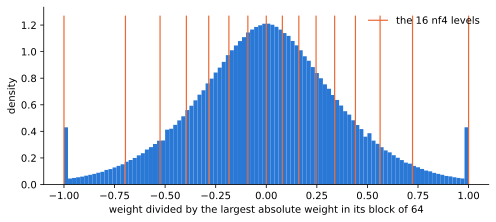

nf4 levels: [-1.    -0.696 -0.525 -0.395 -0.284 -0.185 -0.091  0.     0.08   0.161
  0.246  0.338  0.441  0.563  0.723  1.   ]
nf4: busiest level holds 10.5%, quietest 1.5%, entropy 3.83 of 4 bits
fp4: busiest level holds 12.9%, quietest 0.0%, entropy 3.66 of 4 bits


In [7]:
blocks = W32.reshape(-1, 64)
scaled = (blocks / blocks.abs().amax(1, keepdim=True)).flatten()      # every value now lies in [-1, 1]
nf4 = states["nf4"].code.float().cpu().numpy()                         # the 16 nf4 levels

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(scaled.cpu().numpy(), bins=100, range=(-1, 1), density=True, color="#2a78d6")
ax.vlines(nf4, 0, ax.get_ylim()[1], color="#eb6834", linewidth=1.2, label="the 16 nf4 levels")
ax.set_xlabel("weight divided by the largest absolute weight in its block of 64")
ax.set_ylabel("density")
ax.legend(frameon=False, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print("nf4 levels:", np.round(nf4, 3))

# How evenly are the 16 levels used? Assign 1 million scaled weights to their nearest level and take the entropy
# (4.00 bits would be perfectly even use).
sample = scaled[torch.randperm(scaled.numel(), device=scaled.device)[:1_000_000]]
for name in ["nf4", "fp4"]:
    code_ = states[name].code.float().to(sample.device)
    share = torch.bincount((sample[:, None] - code_[None, :]).abs().argmin(1), minlength=16).float()
    share /= share.sum()
    entropy = -(share[share > 0] * share[share > 0].log2()).sum().item()
    print(f"{name}: busiest level holds {share.max():.1%}, quietest {share.min():.1%}, entropy {entropy:.2f} of 4 bits")
del W, W32, X, Y, blocks, scaled, sample
free_gpu()

## 2. What does 4-bit cost?

The lesson 4 run again, with one change: the frozen base is loaded in 4-bit nf4 with double quantisation, and the
matrix products run in fp16 (`bnb_4bit_compute_dtype`): each layer's weights are rebuilt to fp16 for the product, used,
and thrown away. Everything else is lesson 4's: the same 8,000 training examples (same seed), rank 16, alpha 32, dropout
0.05, all linear layers, learning rate 2e-4 with cosine decay and 3% warm-up, 8 examples per step with 2 accumulation
steps, 256 tokens at most, loss on the answer only, one epoch of 500 steps.

Two effects are expected, and both are measured below: less memory for the frozen weights, and more time per step for
rebuilding them. The comparison uses the numbers lesson 4 measured. They are constants here, not re-run.

In [8]:
# Measured in lesson 4 on the same 500 test examples. Constants: nothing in this cell runs a model.
L4 = {
    "1.5B zero-shot": {"runs": 0.962, "exact": 0.584, "ms per example": 114},                    # also 3-shot: 96.0 / 59.4 / 159 ms
    "1.5B LoRA fp16": {"runs": 0.990, "exact": 0.718, "ms per example": 203,                     # adapter not merged
                       "minutes": 14.6, "tokens per second": 1089, "peak GB": 9.87, "adapter MB": 73.9},
}

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)


def load_4bit(model_id):
    """The base model with its linear layers quantised to 4-bit as they load. Embeddings and norms stay fp16."""
    # device_map takes the GPU number (0), not "cuda": accelerate 1.6.0 reads the index of a 4-bit model's device
    # and fails on "cuda", which has none.
    return AutoModelForCausalLM.from_pretrained(model_id, quantization_config=bnb_config,
                                                torch_dtype=DTYPE, device_map={"": 0})


train_rows = random.Random(SEED).sample(rows["train"], N_TRAIN)          # lesson 4's 8,000 examples
train_ds = Dataset.from_list([messages(r) for r in train_rows])
val_ds = Dataset.from_list([messages(r) for r in random.Random(SEED).sample(rows["validation"], N_VAL)])

free_gpu()
torch.cuda.reset_peak_memory_stats()
model = load_4bit(MODEL_ID)
model.config.use_cache = False       # incompatible with gradient checkpointing
print(f"after loading the 1.5B model in 4-bit: {torch.cuda.memory_allocated() / GB:.2f} GB allocated "
      f"(fp16 would be {1.544 * 2:.2f} GB)")

lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")

config = SFTConfig(
    output_dir="sft-out",
    # 8 examples per step x 2 accumulation steps = an effective batch of 16.
    per_device_train_batch_size=8, gradient_accumulation_steps=2, per_device_eval_batch_size=8,
    num_train_epochs=1, learning_rate=2e-4, lr_scheduler_type="cosine", warmup_ratio=0.03,
    fp16=True, bf16=False,                                  # a T4 has no bfloat16; SFTConfig would otherwise default to it
    gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    max_length=256,                                         # lesson 3: covers over 99.9% of the examples
    completion_only_loss=True,                              # loss on the assistant's answer only
    logging_steps=25, eval_strategy="steps", eval_steps=200,
    save_strategy="no", report_to="none", seed=SEED,
)
# As in lesson 4, peft_config is passed. For a 4-bit model TRL 0.19.1 then calls peft's prepare_model_for_kbit_training
# before adding the adapter. Section 4 looks at what that does.
trainer = SFTTrainer(model=model, args=config, train_dataset=train_ds, eval_dataset=val_ds,
                     processing_class=tok, peft_config=lora)
n_trainable, n_all = trainer.model.get_nb_trainable_parameters()
print(f"trainable parameters: {n_trainable:,} of {n_all:,} ({n_trainable / n_all:.2%})")
print("parameter storage by dtype, GB:", footprint(trainer.model))

after loading the 1.5B model in 4-bit: 1.24 GB allocated (fp16 would be 3.09 GB)


trainable parameters: 18,464,768 of 1,562,179,072 (1.18%)
parameter storage by dtype, GB: {'float32': 1.01, 'uint8': 0.66}


The storage line above shows `uint8` (the packed 4-bit weights), `float32` (the adapter, and more than the adapter:
section 4 explains) and `float16`. Next, lesson 4's proof that the loss ignores the prompt, unchanged. The 4-bit base
does not change the tokenised data, so the counts must come out the same way.

In [9]:
def token_ids(ex):
    """Lesson 3's split: token ids of the prompt (ending with the generation prompt) and of the answer."""
    p = tok.apply_chat_template(ex["prompt"], tokenize=False, add_generation_prompt=True)
    full = tok.apply_chat_template(ex["prompt"] + ex["completion"], tokenize=False)
    p_ids = tok(p, add_special_tokens=False)["input_ids"]
    f_ids = tok(full, add_special_tokens=False)["input_ids"]
    return p_ids, f_ids[len(p_ids):]


# TRL tokenises the prompt without the assistant header ("<|im_start|>assistant\n"), so that header is trained on too.
header = (len(tok.apply_chat_template(train_ds[0]["prompt"], add_generation_prompt=True))
          - len(tok.apply_chat_template(train_ds[0]["prompt"])))

batch = trainer.data_collator([trainer.train_dataset[i] for i in range(4)])
table_ = []
for i in range(4):
    labels, real = batch["labels"][i], batch["attention_mask"][i].bool()
    p_ids, a_ids = token_ids(train_ds[i])
    table_.append({"example": i, "tokens": int(real.sum()),
                   "labels = -100 (no loss)": int((labels[real] == -100).sum()),
                   "labels trained on": int((labels != -100).sum()),
                   "lesson 3: prompt tokens": len(p_ids), "lesson 3: answer tokens": len(a_ids)})
print(pd.DataFrame(table_).to_string(index=False))
print(f"\nThe assistant header is {header} tokens, so trained = answer + {header} and no-loss = prompt - {header}.")
for t in table_:
    assert t["labels trained on"] == t["lesson 3: answer tokens"] + header
    assert t["labels = -100 (no loss)"] == t["lesson 3: prompt tokens"] - header

 example  tokens  labels = -100 (no loss)  labels trained on  lesson 3: prompt tokens  lesson 3: answer tokens
       0     102                       70                 32                       73                       29
       1      63                       43                 20                       46                       17
       2     116                       76                 40                       79                       37
       3     100                       64                 36                       67                       33

The assistant header is 3 tokens, so trained = answer + 3 and no-loss = prompt - 3.


In [10]:
def padded_token_count(dataset, per_device):
    """Tokens the GPU processes: every example is padded to the longest in its batch (batches in random order)."""
    lens = np.array([len(x) for x in dataset["input_ids"]])
    shuffled = np.random.default_rng(SEED).permutation(lens)
    return lens, int(sum(max(shuffled[i:i + per_device]) * len(shuffled[i:i + per_device])
                         for i in range(0, len(shuffled), per_device)))


lens, padded_tokens = padded_token_count(trainer.train_dataset, 8)
print(f"{len(lens):,} examples, {lens.sum():,} real tokens, about {padded_tokens:,} with padding, "
      f"{len(lens) // 16} optimizer steps")
print(f"lesson 4 measured {L4['1.5B LoRA fp16']['tokens per second']:,} tokens per second and "
      f"{L4['1.5B LoRA fp16']['minutes']} minutes. Rebuilding 4-bit weights adds work, so expect this run to be slower.")

8,000 examples, 738,225 real tokens, about 953,928 with padding, 500 optimizer steps


lesson 4 measured 1,089 tokens per second and 14.6 minutes. Rebuilding 4-bit weights adds work, so expect this run to be slower.


In [11]:
free_gpu()
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
trainer.train()
train_secs = time.perf_counter() - start
peak_alloc, peak_reserved = torch.cuda.max_memory_allocated() / GB, torch.cuda.max_memory_reserved() / GB
print(f"\ntraining took {train_secs / 60:.1f} minutes (including the validation passes), "
      f"about {padded_tokens / train_secs:,.0f} padded tokens per second "
      f"(lesson 4, LoRA fp16: {L4['1.5B LoRA fp16']['minutes']} minutes, {L4['1.5B LoRA fp16']['tokens per second']:,} per second)")
print(f"peak GPU memory during training: {peak_alloc:.2f} GB allocated, {peak_reserved:.2f} GB reserved "
      f"(lesson 4: {L4['1.5B LoRA fp16']['peak GB']} GB allocated)")

Step,Training Loss,Validation Loss
200,0.030700,0.031405
400,0.028800,0.023717



training took 19.4 minutes (including the validation passes), about 819 padded tokens per second (lesson 4, LoRA fp16: 14.6 minutes, 1,089 per second)
peak GPU memory during training: 6.01 GB allocated, 14.96 GB reserved (lesson 4: 9.87 GB allocated)


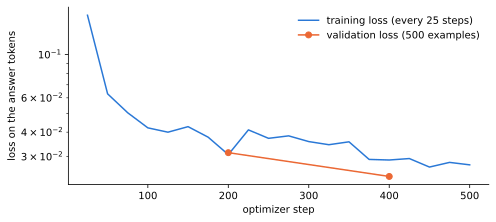

 step  eval_loss
  200   0.031405
  400   0.023717


In [12]:
log = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(figsize=(7, 3.2))
tr = log.dropna(subset=["loss"])
ev = log.dropna(subset=["eval_loss"])
ax.plot(tr["step"], tr["loss"], color="#2a78d6", label="training loss (every 25 steps)")
ax.plot(ev["step"], ev["eval_loss"], "o-", color="#eb6834", label="validation loss (500 examples)")
ax.set_xlabel("optimizer step")
ax.set_ylabel("loss on the answer tokens")
ax.set_yscale("log")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print(ev[["step", "eval_loss"]].to_string(index=False))

Save the adapter, free the training model, and load the saved adapter on a **fresh 4-bit copy** of the base model, as
lesson 4 did with the fp16 base. That scores exactly what was saved. The adapter was trained against the 4-bit weights, so
it is also scored on them: a 4-bit base is part of what the adapter was fitted to.

In [13]:
trainer.model.save_pretrained("adapter-1.5b-qlora")
adapter_mb = sum(os.path.getsize(os.path.join("adapter-1.5b-qlora", f)) for f in os.listdir("adapter-1.5b-qlora")) / 1e6
train_stats["1.5B QLoRA"] = {"minutes": train_secs / 60, "n_train": N_TRAIN, "peak GB": peak_alloc, "adapter MB": adapter_mb,
                             "tokens per second": padded_tokens / train_secs}
print(f"adapter on disk: {adapter_mb:.1f} MB; trainable parameters {n_trainable:,}")

del trainer, model
free_gpu()

tuned = PeftModel.from_pretrained(load_4bit(MODEL_ID), "adapter-1.5b-qlora").eval()
evaluate("1.5B QLoRA", tuned, tok)
print("(adapter not merged, zero-shot prompt, 4-bit base. Lesson 4's LoRA on the fp16 base: "
      "runs 99.0%, exact 71.8%, 203 ms per example)")
del tuned
free_gpu()

adapter on disk: 73.9 MB; trainable parameters 18,464,768


1.5B QLoRA     runs 99.4%  exact 71.8%  307 ms per example
(adapter not merged, zero-shot prompt, 4-bit base. Lesson 4's LoRA on the fp16 base: runs 99.0%, exact 71.8%, 203 ms per example)


## 3. Why does the 7B model not fit with plain LoRA?

LoRA freezes the base weights but they still have to sit in GPU memory. For Qwen2.5-7B-Instruct that is the whole
model in fp16, before a single activation or optimizer state is added. The parameter count below is computed from the
model's configuration (no weights are downloaded), and the 4-bit size uses the bytes per weight measured in section 1.

In [14]:
def count_parameters(cfg):
    """Parameters of a Llama-style decoder (Qwen2 and Llama): the linear layers, and the embedding and output head."""
    h, kv = cfg.hidden_size, cfg.num_key_value_heads * (cfg.hidden_size // cfg.num_attention_heads)
    attention = 2 * h * h + 2 * h * kv                       # q and o are h x h; k and v are h x kv
    mlp = 3 * h * cfg.intermediate_size                      # gate, up and down
    linear = cfg.num_hidden_layers * (attention + mlp)
    embedding = cfg.vocab_size * h
    head = 0 if cfg.tie_word_embeddings else embedding        # the output head, when it is not shared with the embedding
    return linear, embedding, head


cfg = AutoConfig.from_pretrained(MODEL_7B)
linear, embedding, head = count_parameters(cfg)
total = linear + embedding + head
card = torch.cuda.get_device_properties(0).total_memory / GB
print(f"{MODEL_7B}: {total / 1e9:.2f}B parameters = {linear / 1e9:.2f}B in linear layers, "
      f"{embedding / 1e9:.2f}B embedding, {head / 1e9:.2f}B output head (embeddings tied: {cfg.tie_word_embeddings})")
print(f"\nGPU memory: {card:.1f} GB")
print(f"fp16, plain LoRA : {total * 2 / GB:5.1f} GB for the weights alone -> no room for activations, adapter or optimizer")
print("                   (lesson 2 measured this: the 7B LoRA run ran out of memory after loading 15.42 GB)")
four_bit = linear * bytes_per_weight / GB + (embedding + head) * 2 / GB
print(f"4-bit, QLoRA     : {four_bit:5.1f} GB = {linear * bytes_per_weight / GB:.1f} GB of 4-bit linear layers "
      f"+ {(embedding + head) * 2 / GB:.1f} GB of fp16 embedding and output head")
print(f"                   leaves about {card - four_bit:.1f} GB for the adapter, its optimizer, activations and the CUDA context")

Qwen/Qwen2.5-7B-Instruct: 7.62B parameters = 6.53B in linear layers, 0.54B embedding, 0.54B output head (embeddings tied: False)

GPU memory: 15.6 GB
fp16, plain LoRA :  15.2 GB for the weights alone -> no room for activations, adapter or optimizer
                   (lesson 2 measured this: the 7B LoRA run ran out of memory after loading 15.42 GB)
4-bit, QLoRA     :   5.5 GB = 3.4 GB of 4-bit linear layers + 2.2 GB of fp16 embedding and output head
                   leaves about 10.1 GB for the adapter, its optimizer, activations and the CUDA context


Note where the 4-bit saving does not reach: bitsandbytes quantises the linear layers only. The token embedding and the
output head (`lm_head`) stay in 16-bit, and in this 7B model they are two separate matrices of 152,064 × 3,584 each.
Together they are 1.09 billion parameters, 2.2 GB in fp16. That matters in the next section.

## 4. The memory trap: `prepare_model_for_kbit_training`

When `SFTTrainer` is given a 4-bit model and a `peft_config` (as in section 2), TRL 0.19.1 first calls peft's
`prepare_model_for_kbit_training`. Among other things, that function **casts every parameter that is not 4-bit and is in
16-bit to float32**: the embedding, the output head and the norm layers. The habit comes from the original QLoRA recipe,
where it protects numerical stability. For the 1.5B model the cost is small. For the 7B model the embedding and the head
double from 2.2 GB to 4.4 GB.

Measure it: load the 7B model in 4-bit (the 15 GB download happens here), read the memory in use, call the helper,
read it again. This load is the slowest cell of the lab on a first run.

In [15]:
free_gpu()
model7 = load_4bit(MODEL_7B)
after_load = torch.cuda.memory_allocated() / GB
print(f"after loading in 4-bit      : {after_load:5.2f} GB   parameters by dtype: {footprint(model7)}")

model7 = prepare_model_for_kbit_training(model7, use_gradient_checkpointing=True,
                                         gradient_checkpointing_kwargs={"use_reentrant": False})
after_prepare = torch.cuda.memory_allocated() / GB
print(f"after prepare_model_for_kbit: {after_prepare:5.2f} GB   parameters by dtype: {footprint(model7)}")
print(f"\nthe helper added {after_prepare - after_load:.2f} GB before any training step")
del model7
free_gpu()

after loading in 4-bit      :  5.65 GB   parameters by dtype: {'float16': 2.18, 'uint8': 3.26}
after prepare_model_for_kbit:  7.83 GB   parameters by dtype: {'float32': 4.36, 'uint8': 3.26}

the helper added 2.18 GB before any training step


The extra memory is permanent, and there is a second cost: the embedding now returns float32, so the hidden states
between the layers are expected to be float32 as well, twice the size of the float16 stream a float16 embedding gives.

On a 15.6 GB card that is the difference between a run that fits and one that does not. Lesson 2 measured a 7B QLoRA step
at 15.2 GB peak (batch 1 × 512 tokens) this way, with no room to raise the batch size.

**The choice in this lab: prepare the model ourselves, and pass a ready PEFT model to the trainer.** The TRL 0.19.1
source (`SFTTrainer.__init__`) calls `_prepare_peft_model`, which holds the call to `prepare_model_for_kbit_training`, only when
`peft_config` is not `None`, so a `PeftModel` passed without a `peft_config` skips it. What the helper did that we still
need, we do by hand:

1. **Gradient checkpointing** with `use_reentrant=False`, as in section 2, and `enable_input_require_grads()`. The second
   is not needed with non-reentrant checkpointing; it is kept because it is what the helper does.
2. **The adapter in float32.** `get_peft_model` upcasts float16 adapter weights to float32 by default
   (`autocast_adapter_dtype=True`). fp16 training needs this: the gradient scaler refuses to unscale float16 gradients.
   The frozen embedding, head and norms stay float16, which is fine because they get no gradients, and PyTorch's
   autocast handles the mixed precision in the forward pass.

The cell below is the function section 5 uses. It checks its own result: every trainable parameter must be float32.

In [16]:
def build_peft_model(model, lora):
    """Attach a LoRA adapter to a 4-bit model without prepare_model_for_kbit_training (see the text above)."""
    model.config.use_cache = False                                   # incompatible with gradient checkpointing
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.enable_input_require_grads()
    peft_model = get_peft_model(model, lora)
    bad = [n for n, p in peft_model.named_parameters() if p.requires_grad and p.dtype != torch.float32]
    assert not bad, f"trainable parameters that are not float32: {bad[:3]}"
    return peft_model

## 5. What does it buy? Qwen2.5-7B-Instruct on the same T4

**Baseline.** The 7B model loaded in 4-bit, with the zero-shot prompt, on the same 500 test examples. The 1.5B baseline
of lesson 4 was measured in fp16; this one is in 4-bit, the only way the 7B model fits, so its time per example includes
the cost of rebuilding the weights at every step of generation.

**Training settings.** The same as the 1.5B run (rank 16, alpha 32, dropout 0.05, all linear layers, learning rate 2e-4,
cosine decay, 3% warm-up, 256 tokens at most, loss on the answer only, one epoch) with two changes forced by memory and time:

- **Batch 4 with 4 accumulation steps.** The effective batch stays 16, so each optimizer step sees as many examples as
  in the 1.5B run, and the learning rate stays valid. The micro-batch is halved because the output of the model is one
  logit for each of 152,064 tokens at every position: 4 × 256 positions in float32 is already 0.6 GB, and the 7B weights
  leave less room than the 1.5B weights did.
- **1,600 training examples instead of 8,000 (the first 1,600 of the same 8,000), 100 optimizer steps.** This is a
  budget decision, set by the free session, and it is a handicap for the 7B model, not an advantage. Estimate of its
  speed: training costs about 6 FLOPs per parameter per token (forward, recomputation under gradient checkpointing, and
  the backward pass through the frozen weights), and the matrix products touch 7.07B parameters (6.53B linear layers +
  0.54B output head, the embedding is a lookup), so about 42 GFLOP per token. Lesson 4 measured 1,089 tokens per second on
  a 1.5B model, which is about 10 TFLOPs, 16% of the T4's 65 TFLOPs fp16 peak; the same efficiency would give about 240
  tokens per second. Rebuilding 6.5B weights three times per micro-batch from 4-bit adds bandwidth-bound work, and a
  micro-batch of 4 is less efficient than one of 8. The estimate is **150 to 250 tokens per second**, so 1,600 examples
  (about 180,000 padded tokens) take **12 to 20 minutes**. The cell before training prints the padded-token count, and
  the cell after prints the measured speed, so `N_TRAIN_7B` can be rescaled.
- **No validation passes** during the 7B run: they cost minutes, and the test examples are the measurement that matters.
  The training time is therefore not exactly comparable with the 1.5B run's, which included two validation passes.

First the baseline.

In [17]:
free_gpu()
model7 = load_4bit(MODEL_7B).eval()
print(f"loaded: {torch.cuda.memory_allocated() / GB:.2f} GB allocated, parameters by dtype {footprint(model7)}")
evaluate("7B zero-shot", model7, tok)

loaded: 5.65 GB allocated, parameters by dtype {'float16': 2.18, 'uint8': 3.26}


7B zero-shot   runs 98.6%  exact 65.2%  385 ms per example


In [18]:
train_ds7 = Dataset.from_list([messages(r) for r in train_rows[:N_TRAIN_7B]])

lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")
peft7 = build_peft_model(model7, lora)
n_trainable7, n_all7 = peft7.get_nb_trainable_parameters()
print(f"trainable parameters: {n_trainable7:,} of {n_all7:,} ({n_trainable7 / n_all7:.2%})")
print("parameter storage by dtype, GB:", footprint(peft7))
print(f"memory in use before training: {torch.cuda.memory_allocated() / GB:.2f} GB")

config7 = SFTConfig(
    output_dir="sft-out-7b",
    # 4 examples per step x 4 accumulation steps = an effective batch of 16, as in the 1.5B run.
    per_device_train_batch_size=4, gradient_accumulation_steps=4,
    num_train_epochs=1, learning_rate=2e-4, lr_scheduler_type="cosine", warmup_ratio=0.03,
    fp16=True, bf16=False,
    gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    max_length=256, completion_only_loss=True,
    logging_steps=10, eval_strategy="no",
    save_strategy="no", report_to="none", seed=SEED,
)
# A ready PeftModel and no peft_config: TRL does not call prepare_model_for_kbit_training (section 4).
trainer7 = SFTTrainer(model=peft7, args=config7, train_dataset=train_ds7, processing_class=tok)

lens7, padded_tokens7 = padded_token_count(trainer7.train_dataset, 4)
print(f"\n{len(lens7):,} examples, {lens7.sum():,} real tokens, about {padded_tokens7:,} with padding, "
      f"{len(lens7) // 16} optimizer steps")
print(f"at 150 to 250 tokens per second: {padded_tokens7 / 250 / 60:.0f} to {padded_tokens7 / 150 / 60:.0f} minutes")

trainable parameters: 40,370,176 of 7,655,986,688 (0.53%)
parameter storage by dtype, GB: {'float16': 2.18, 'float32': 0.16, 'uint8': 3.26}
memory in use before training: 5.82 GB



1,600 examples, 147,591 real tokens, about 175,736 with padding, 100 optimizer steps
at 150 to 250 tokens per second: 12 to 20 minutes


In [19]:
free_gpu()
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
trainer7.train()
train_secs7 = time.perf_counter() - start
peak7, peak7_reserved = torch.cuda.max_memory_allocated() / GB, torch.cuda.max_memory_reserved() / GB
print(f"\ntraining took {train_secs7 / 60:.1f} minutes, about {padded_tokens7 / train_secs7:,.0f} padded tokens per second")
print(f"peak GPU memory during training: {peak7:.2f} GB allocated, {peak7_reserved:.2f} GB reserved")
log7 = pd.DataFrame(trainer7.state.log_history).dropna(subset=["loss"])
print(log7[["step", "loss"]].to_string(index=False))

Step,Training Loss
10,0.268900
20,0.057800
30,0.036600
40,0.042900
50,0.033500
60,0.027700
70,0.034100
80,0.042800
90,0.037800
100,0.042600



training took 12.3 minutes, about 237 padded tokens per second
peak GPU memory during training: 8.07 GB allocated, 9.62 GB reserved
 step   loss
   10 0.2689
   20 0.0578
   30 0.0366
   40 0.0429
   50 0.0335
   60 0.0277
   70 0.0341
   80 0.0428
   90 0.0378
  100 0.0426


Save the adapter, free everything, and score it on a fresh 4-bit copy of the base, as in section 2.

In [20]:
trainer7.model.save_pretrained("adapter-7b-qlora")
adapter7_mb = sum(os.path.getsize(os.path.join("adapter-7b-qlora", f)) for f in os.listdir("adapter-7b-qlora")) / 1e6
train_stats["7B QLoRA"] = {"minutes": train_secs7 / 60, "n_train": N_TRAIN_7B, "peak GB": peak7, "adapter MB": adapter7_mb,
                           "tokens per second": padded_tokens7 / train_secs7}
print(f"adapter on disk: {adapter7_mb:.1f} MB; trainable parameters {n_trainable7:,}")

del trainer7, peft7, model7
free_gpu()

tuned7 = PeftModel.from_pretrained(load_4bit(MODEL_7B), "adapter-7b-qlora").eval()
evaluate("7B QLoRA", tuned7, tok)
del tuned7
free_gpu()

adapter on disk: 161.5 MB; trainable parameters 40,370,176


7B QLoRA       runs 98.0%  exact 73.4%  427 ms per example


## 6. Is it worth it?

The five systems on the same 500 examples. The two lesson 4 rows are the numbers measured in lesson 4, not re-run. The ±
column is the 95% interval on the exact-match rate, $1.96\sqrt{p(1-p)/n}$ with n = 500 (lesson 3): differences smaller than
that are not evidence. Training minutes are not strictly comparable across rows: lesson 4 and the 1.5B QLoRA run include two
validation passes, the 7B run has none, and the 7B run trains on 1,600 examples, not 8,000.

In [21]:
systems = {"1.5B zero-shot": {**L4["1.5B zero-shot"], "n_train": None},
           "1.5B LoRA fp16": {**L4["1.5B LoRA fp16"], "n_train": 8000},
           "1.5B QLoRA": {**results["1.5B QLoRA"], **train_stats["1.5B QLoRA"]},
           "7B zero-shot": {**results["7B zero-shot"], "n_train": None},
           "7B QLoRA": {**results["7B QLoRA"], **train_stats["7B QLoRA"]}}
table = pd.DataFrame(systems).T
table["exact ±"] = 1.96 * np.sqrt(table["exact"].astype(float) * (1 - table["exact"].astype(float)) / N_TEST)
view = pd.DataFrame({
    "runs, %": (table["runs"].astype(float) * 100).round(1),
    "exact match, %": (table["exact"].astype(float) * 100).round(1),
    "exact ±, points": (table["exact ±"] * 100).round(1),
    "ms per example": table["ms per example"].astype(float).round(0),
    "training, min": table["minutes"].astype(float).round(1),
    "training examples": table["n_train"],
    "peak GB": table["peak GB"].astype(float).round(2),
    "adapter, MB": table["adapter MB"].astype(float).round(1),
})
print(view.fillna("-").to_string())
print("\n1.5B zero-shot and 1.5B LoRA fp16: measured in lesson 4. Zero-shot rows run on fp16 (1.5B) and 4-bit (7B) weights.")

                runs, %  exact match, %  exact ±, points  ms per example training, min training examples peak GB adapter, MB
1.5B zero-shot     96.2            58.4              4.3           114.0             -                 -       -           -
1.5B LoRA fp16     99.0            71.8              3.9           203.0          14.6            8000.0    9.87        73.9
1.5B QLoRA         99.4            71.8              3.9           307.0          19.4            8000.0    6.01        73.9
7B zero-shot       98.6            65.2              4.2           385.0             -                 -       -           -
7B QLoRA           98.0            73.4              3.9           427.0          12.3            1600.0    8.07       161.5

1.5B zero-shot and 1.5B LoRA fp16: measured in lesson 4. Zero-shot rows run on fp16 (1.5B) and 4-bit (7B) weights.


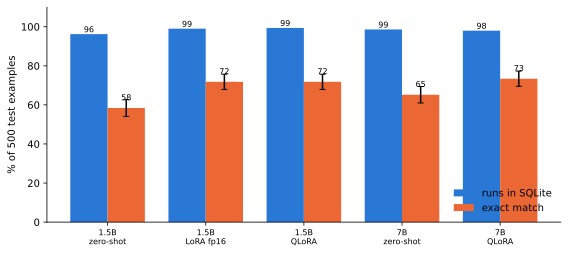

In [22]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(view))
w = 0.38
runs_, exact_ = view["runs, %"], view["exact match, %"]
ax.bar(x - w / 2, runs_, w, color="#2a78d6", label="runs in SQLite")
ax.bar(x + w / 2, exact_, w, yerr=view["exact ±, points"], capsize=3, color="#eb6834", label="exact match")
for i, (a, b) in enumerate(zip(runs_, exact_)):
    ax.text(i - w / 2, a + 1, f"{a:.0f}", ha="center", fontsize=8)
    ax.text(i + w / 2, b + 4, f"{b:.0f}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([n.replace(" ", "\n", 1) for n in view.index], fontsize=8)
ax.set_ylabel("% of 500 test examples")
ax.set_ylim(0, 110)
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### What is still wrong?

The failures of the two QLoRA models, sorted into causes by lesson 4's rules, tried in this order: **does not run**
(SQLite rejects the query), **wrong value or literal** (same shape once literals are removed), **wrong aggregate,
operator or clause**, **wrong column or table**, **other** (the same parts written another way). Exact match is strict,
so some of these are correct queries in another form.

In [23]:
KEYWORDS = {"count", "sum", "avg", "min", "max", "distinct", "order", "group", "by", "desc", "asc", "limit", "having",
            "join", "union", "intersect", "except", "not", "in", "like", "between", "and", "or", "null",
            ">", "<", ">=", "<=", "=", "!=", "<>"}


def shape(sql):
    """The query with literal values removed (lesson 3)."""
    sql = re.sub(r"\"[^\"]*\"|'[^']*'", "V", sql)
    return normalise(re.sub(r"\b\d+(\.\d+)?\b", "N", sql))


def parts(sql):
    return re.findall(r"[a-z_]\w*|<>|!=|>=|<=|[=<>]", shape(sql))


def cause(row, gold, context):
    if row["error"]:
        return "does not run"
    if shape(row["sql"]) == shape(gold):
        return "wrong value or literal"
    got, want = parts(row["sql"]), parts(gold)
    if sorted(t for t in got if t in KEYWORDS) != sorted(t for t in want if t in KEYWORDS):
        return "wrong aggregate, operator or clause"
    schema = set(re.findall(r"[a-z_]\w*", context.lower())) - KEYWORDS
    if {t for t in got if t in schema} != {t for t in want if t in schema}:
        return "wrong column or table"
    return "other"


for name in ["1.5B QLoRA", "7B QLoRA"]:
    df = scored[name]
    df["cause"] = [cause(row, r["answer"], r["context"]) if not row["exact"] else "exact match"
                   for (_, row), r in zip(df.iterrows(), test)]
order = ["exact match", "does not run", "wrong value or literal", "wrong aggregate, operator or clause",
         "wrong column or table", "other"]
causes = pd.DataFrame({name: scored[name]["cause"].value_counts() for name in ["1.5B QLoRA", "7B QLoRA"]})
print(causes.reindex(order).fillna(0).astype(int).to_string())

                                     1.5B QLoRA  7B QLoRA
cause                                                    
exact match                                 359       367
does not run                                  3        10
wrong value or literal                       15        17
wrong aggregate, operator or clause          62        49
wrong column or table                         2         0
other                                        59        57


In [24]:
fails = scored["7B QLoRA"].query("cause != 'exact match'")
for i, row in fails.sample(min(5, len(fails)), random_state=SEED).iterrows():
    print(f"[{row['cause']}]")
    print("question:", test[i]["question"])
    print("gold    :", test[i]["answer"])
    print("model   :", row["sql"], "\n")

[other]
question: Who directed episode 11 in the series?
gold    : SELECT directed_by FROM table_26136228_3 WHERE series_no = 11
model   : SELECT directed_by FROM table_26136228_3 WHERE series_no = "11" 

[wrong value or literal]
question: What is the place when the player is Bob Gilder and the money was $20,903?
gold    : SELECT place FROM table_name_88 WHERE money___$__ = "20,903" AND player = "bob gilder"
model   : SELECT place FROM table_name_88 WHERE money___$__ = "$20,903" AND player = "bob gilder" 

[other]
question: Which Score has a Home of quebec nordiques, and a Visitor of vancouver blazers on february 28?
gold    : SELECT score FROM table_name_52 WHERE home = "quebec nordiques" AND visitor = "vancouver blazers" AND date = "february 28"
model   : SELECT score FROM table_name_52 WHERE date = "february 28" AND home = "quebec nordiques" AND visitor = "vancouver blazers" 

[wrong aggregate, operator or clause]
question: What's the rank when the obese children and adolescent coun

## 7. What do we keep?

Two adapters, `adapter-1.5b-qlora` and `adapter-7b-qlora`. Each holds only the LoRA matrices and their configuration.
An adapter is loaded on top of the base model it was trained on, and here that base was the **4-bit** copy: load the
base with the same `BitsAndBytesConfig` as `load_4bit` above, then `PeftModel.from_pretrained`. The adapter's own
configuration records the base model's name but not how it was quantised. Merging the adapter into a 4-bit base is
possible, but peft warns that it rounds the result, so the generations can differ from the ones measured here; the adapters
here were scored unmerged. In Colab, download them from the Files panel on the left.

In [25]:
for d in ["adapter-1.5b-qlora", "adapter-7b-qlora"]:
    print(d)
    for f in sorted(os.listdir(d)):
        print(f"  {os.path.getsize(os.path.join(d, f)) / 1e6:8.2f} MB  {f}")
    print("  base model:", json.load(open(os.path.join(d, "adapter_config.json")))["base_model_name_or_path"])

adapter-1.5b-qlora
      0.01 MB  README.md
      0.00 MB  adapter_config.json
     73.91 MB  adapter_model.safetensors
  base model: Qwen/Qwen2.5-1.5B-Instruct
adapter-7b-qlora
      0.01 MB  README.md
      0.00 MB  adapter_config.json
    161.53 MB  adapter_model.safetensors
  base model: Qwen/Qwen2.5-7B-Instruct


## Read the result

- **Check the two sides of the trade.** The 4-bit base is measured on both: memory (section 2 against lesson 4, and the
  7B model that fits at all) and quality and speed (the table). Read the 1.5B QLoRA row against the 1.5B LoRA row first:
  that is the price of 4-bit with everything else equal.
- **Read the 7B rows with their handicaps in mind.** The 7B model saw 1,600 examples, not 8,000, and was scored on a 4-bit
  base. A difference between the 7B and 1.5B QLoRA rows smaller than the ± column is not evidence.
- **Know what the helper does to memory.** The float32 cast of the embedding and the output head is the difference in
  section 4. A 7B run that ran out of memory at the first step may be this, not the model size.
- **Look at the failures.** The cause table says whether a larger model fixes the kinds of mistakes the small one made, or
  only some of them.
- **Cost:** two adapters of tens of megabytes, trained on a free GPU in one session.

The lesson explains each result: [QLoRA: a bigger model on a small GPU](https://docs.recohut.com/courses/llm-fine-tuning/2-train/05-qlora).